Bentuk data awal: 569 baris x 30 fitur

--- Evaluasi Komponen Utama ---
Varians PC1 : 44.27%
Varians PC2 : 18.97%
Total Informasi Terjaga (2D): 63.24% dari 30 fitur awal


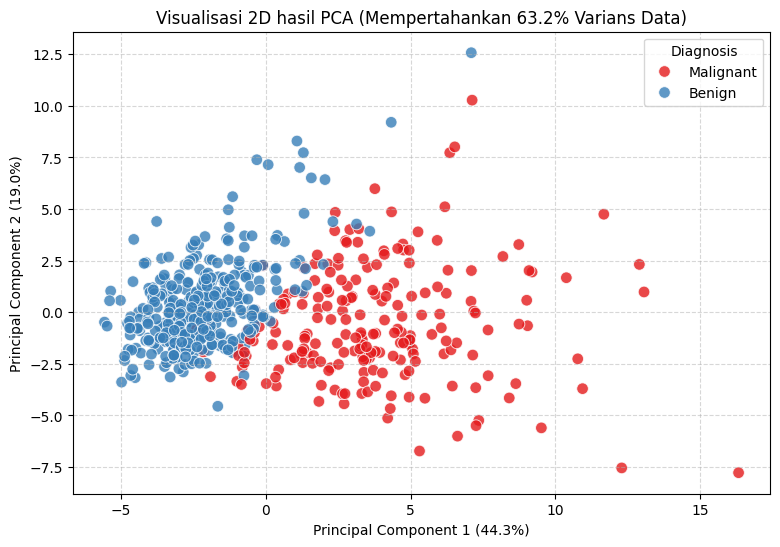

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

# 1. LOAD DATASET ( Breast Cancer - 30 Fitur Numerik )
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target  # 0 = Malignant (Ganas), 1 = Benign (Jinak)

print(f"Bentuk data awal: {X.shape[0]} baris x {X.shape[1]} fitur")


# 2. PREPROCESSING & FEATURE SCALING (WAJIB UNTUK PCA)
# PCA sangat sensitif terhadap skala fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 3. TRAINING PCA (REDUKSI DARI 30 FITUR MENJADI 2 FITUR UTAMA)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["Target"] = y
df_pca["Diagnosis"] = df_pca["Target"].map({0: "Malignant", 1: "Benign"})


# 4. EVALUASI: EXPLAINED VARIANCE RATIO
varians = pca.explained_variance_ratio_
total_varians = np.sum(varians) * 100

print("\n--- Evaluasi Komponen Utama ---")
print(f"Varians PC1 : {varians[0]*100:.2f}%")
print(f"Varians PC2 : {varians[1]*100:.2f}%")
print(f"Total Informasi Terjaga (2D): {total_varians:.2f}% dari 30 fitur awal")


# 5. VISUALISASI HASIL REDUKSI PCA (2D SCATTER PLOT)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    palette="Set1",
    s=70,
    alpha=0.8,
)

plt.title(f"Visualisasi 2D hasil PCA (Mempertahankan {total_varians:.1f}% Varians Data)")
plt.xlabel(f"Principal Component 1 ({varians[0]*100:.1f}%)")
plt.ylabel(f"Principal Component 2 ({varians[1]*100:.1f}%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

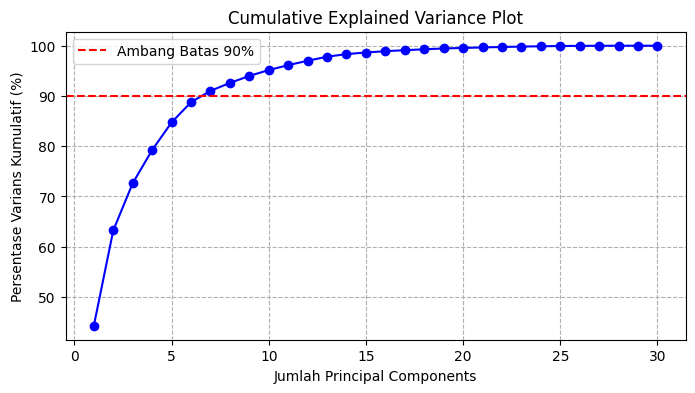

In [2]:
# Hitung varians untuk semua 30 komponen
pca_full = PCA().fit(X_scaled)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker="o", color="b")
plt.axhline(y=90, color="r", linestyle="--", label="Ambang Batas 90%")
plt.title("Cumulative Explained Variance Plot")
plt.xlabel("Jumlah Principal Components")
plt.ylabel("Persentase Varians Kumulatif (%)")
plt.grid(True, linestyle="--")
plt.legend()
plt.show()